# Walkthrough: a promotion analysis with the test plan written first

This notebook **does not open the holdout**. It reads the files the pipeline already
wrote (`results/`), so it can be re-run any number of times without breaking the
one-opening rule. To produce those files, run `python run_all.py` from the project folder.

Order of events, which the git history proves:
1. `HYPOTHESES.md` committed (the plan)
2. data generator and the sealed split
3. exploration on training data only
4. the one-time holdout script
5. the holdout opened once

In [1]:
import json, subprocess
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print(subprocess.run(["git", "log", "--reverse", "--format=%h %ad %s", "--date=format:%Y-%m-%d %H:%M"],
                     cwd=ROOT, capture_output=True, text=True).stdout)

d896797 2026-10-20 10:22 Pre-register 5 hypotheses, tests, alpha, Holm correction and holdout rule before any data or analysis code exists
ebdae63 2026-10-20 10:23 Add seeded synthetic data generator (Rossmann layout) and train/holdout split that fingerprints and seals the holdout
7b71140 2026-10-20 10:24 Fix holdout start to the first day of a calendar month, matching rule 1 (holdout not yet opened)
553e1ac 2026-10-20 10:25 Add shared features, the 5 pre-registered tests with Holm correction, and a training-only exploratory dry run; log the H4 season weakness before opening the holdout
7a8e40a 2026-10-20 10:26 Add the one-time holdout script (fingerprint check, plan-committed check, lock written before reading) and run_all.py; holdout still unopened
67dd484 2026-10-20 10:27 Before opening the holdout: report untestable tests as did-not-hold (logged as Deviation 1), fix the effects chart, add a results-only walkthrough notebook. Found by rehearsing on a fake holdout cut from training.


## 1. The split
The last 3 calendar months were sealed and fingerprinted before any test code existed.

In [2]:
split = json.load(open(ROOT / "results/split_info.json"))
lock = sorted((ROOT / "results").glob("holdout_opened_*.json"))
pd.Series({**split, "holdout opened at": json.load(open(lock[-1]))["opened_at"] if lock else "not yet"})

source_file                                       data/store_sales.csv
source_sha256        57dca21f2027b06c9313146ce73d828099ea32eaa79619...
train_start                                                 2024-01-01
train_end                                                   2026-03-31
holdout_start                                               2026-04-01
holdout_end                                                 2026-06-30
train_rows                                                       49260
holdout_rows                                                      5460
holdout_sha256       f3d6d6450b022678d66e2e7f7c010ce277317c347137ea...
holdout opened at                                  2026-10-20T10:27:29
dtype: object

## 2. Exploration (training window only)
The grey box is the holdout. It was left blank on purpose.

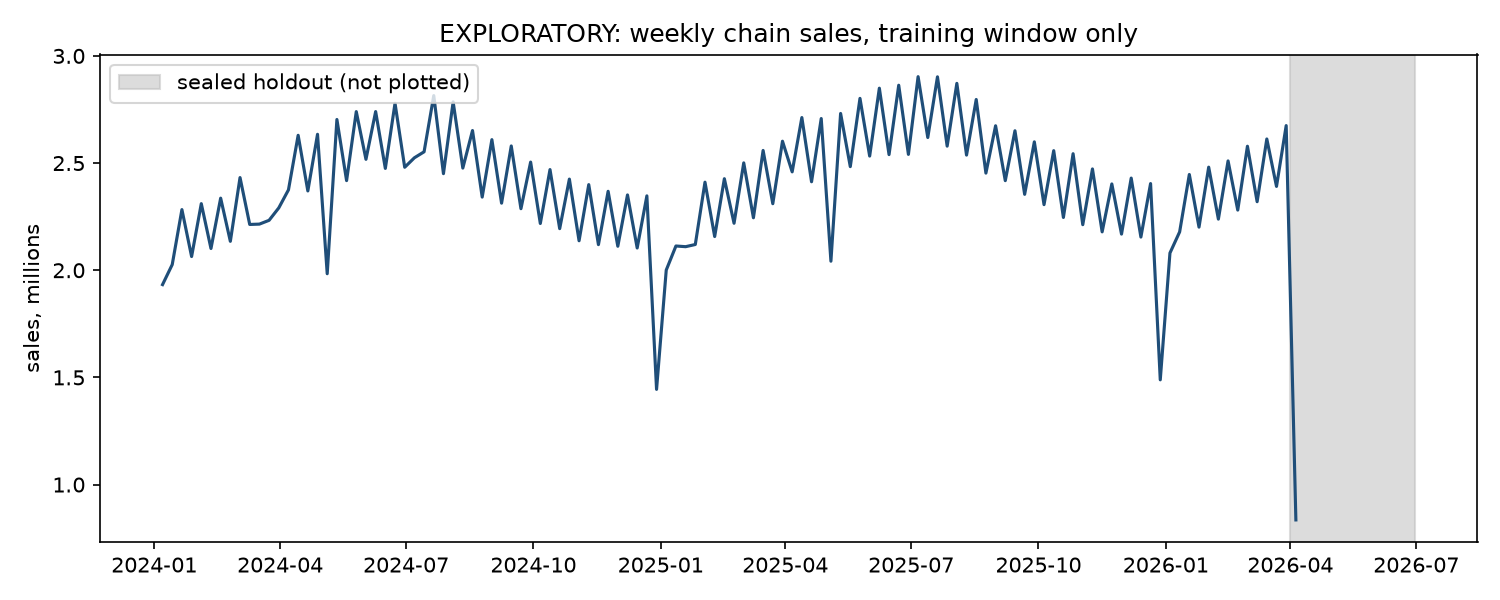

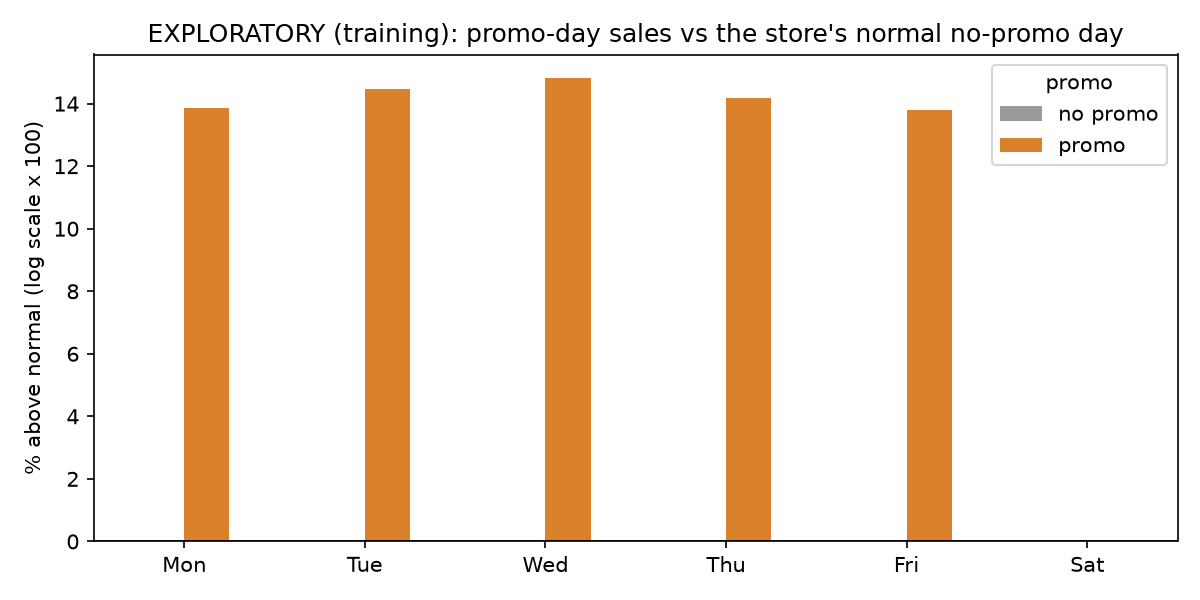

In [3]:
display(Image(ROOT / "results/charts/01_train_weekly_sales.png"))
display(Image(ROOT / "results/charts/02_train_weekday_promo.png"))

## 3. The result: all 5 hypotheses, nulls included

In [4]:
display(Markdown(open(ROOT / "results/RESULTS.md").read()))

# Results: sealed holdout, opened once

Holdout 2026-04-01 to 2026-06-30, 60 stores, 4,601 open store-days. Opened 2026-10-20T10:27:29.
Plan first committed: `d896797e2af18119e8e725ec31acfb09e8522a97 2026-10-20T10:22:55-07:00`.

**3 of 5 hypotheses held and 2 did not**, at a family-wise alpha of 0.05 with Holm-Bonferroni correction. Every hypothesis is listed, including the nulls.

| # | Hypothesis | Effect | 95% CI | Stores | p (raw) | p (Holm) | Wilcoxon p | Verdict | Flags |
|---|---|---|---|---|---|---|---|---|---|
| H1 | Promotions raise daily sales | +14.5% | +12.9% to +16.2% | 60 (0 dropped) | 1.4e-27 | 5.8e-27 | 8.1e-12 | **held** | none |
| H2 | Promotions raise customer traffic | +15.4% | +13.8% to +17.0% | 60 (0 dropped) | 1.2e-28 | 6e-28 | 8.1e-12 | **held** | none |
| H3 | Promotions raise basket size | -0.7% | -1.0% to -0.4% | 60 (0 dropped) | 1 | 1 | 1 | **did not hold** | none |
| H4 | Sales lift is larger during school holidays | -5.1% | -6.7% to -3.4% | 46 (14 dropped) | 1 | 1 | 1 | **did not hold** | none |
| H5 | Day after a promo sells less (pull-forward) | -2.7% | -3.9% to -1.6% | 60 (0 dropped) | 1.1e-05 | 3.3e-05 | 4.1e-05 | **held** | none |

Effect = average across stores, as a percentage. For H4 it is the extra lift inside school holidays; for H5 it is the day-after-promo gap versus other non-promo days. The CI is two-sided and not corrected; the verdict uses only the Holm p-value.


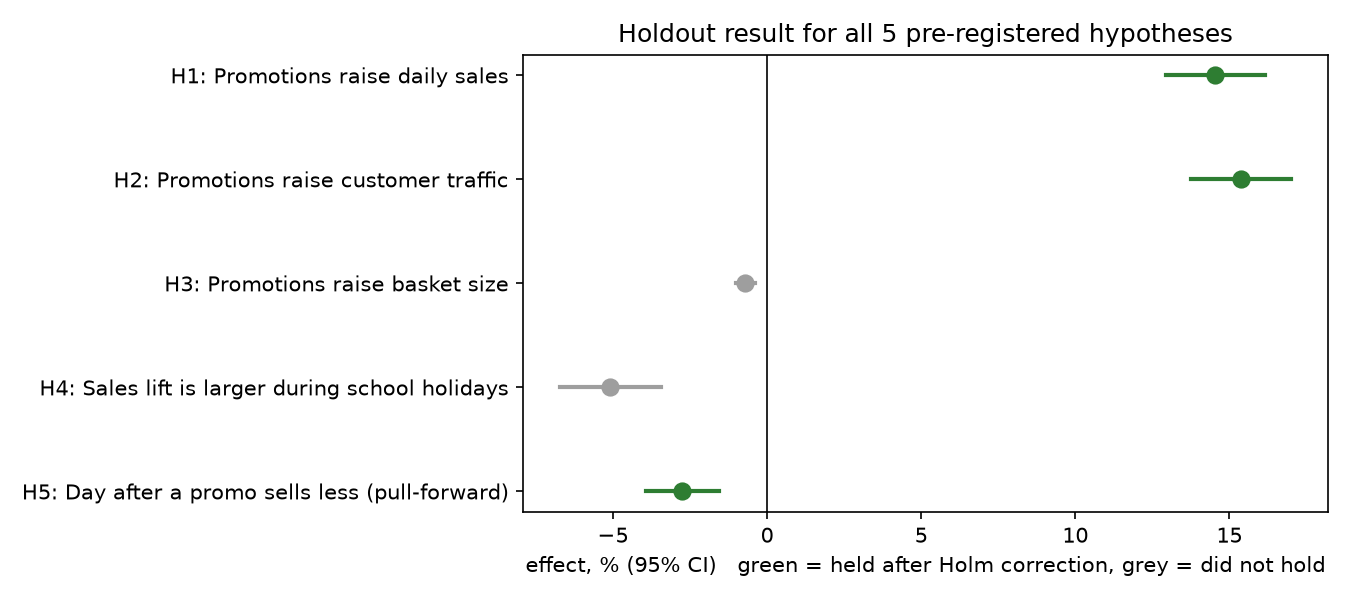

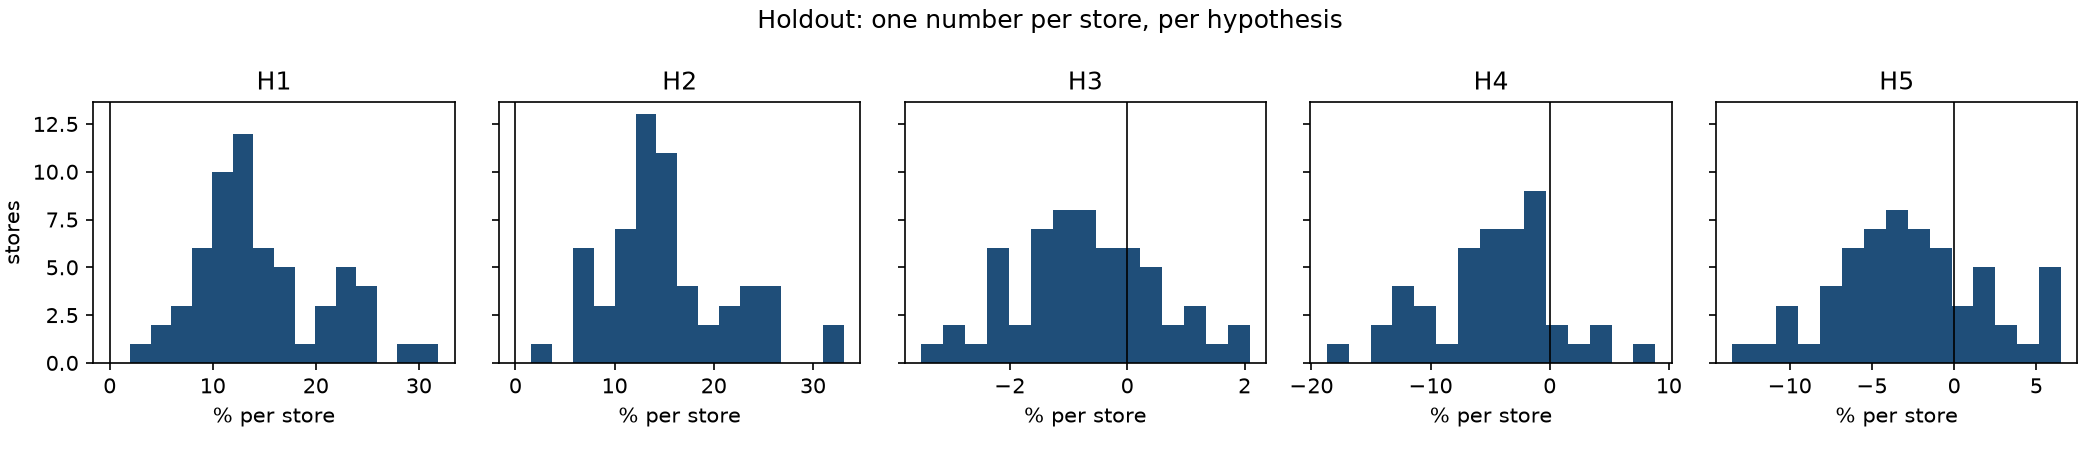

In [5]:
display(Image(ROOT / "results/charts/03_holdout_effects.png"))
display(Image(ROOT / "results/charts/04_holdout_per_store.png"))

## 4. Training dry run vs holdout
If the training (in-sample) numbers were much bigger than the holdout numbers, that would be a sign of over-fitting the baseline.

In [6]:
train = pd.read_csv(ROOT / "results/exploratory_train_tests.csv").set_index("id")
hold = pd.read_csv(ROOT / "results/results_table.csv").set_index("id")
pd.DataFrame({"training effect %": train["effect_pct"].round(1),
              "holdout effect %": hold["effect_pct"].round(1),
              "holdout verdict": hold["verdict"]})

,training effect %,holdout effect %,holdout verdict
id,,,
H1,15.3,14.5,held
H2,16.5,15.4,held
H3,-1.0,-0.7,did not hold
H4,-2.8,-5.1,did not hold
H5,-2.0,-2.7,held
